# Bolivia: análisis municipal del Censo 2024
**Fuente:** INE, archivo POBLACIÓN.xlsx, cuadros 1, 7 y 8. **Unidad de análisis:** municipio/TIOC (n = 343).

El CSV derivado conserva registros municipales de 2024. Los años 2001 y 2012 son referencias históricas. No se infiere causalidad.

In [80]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

carpeta_exportaciones = Path("exportaciones")
carpeta_exportaciones.mkdir(exist_ok=True)
contador_tablas = 0

def mostrar_y_exportar_tabla(tabla, nombre):
    global contador_tablas
    contador_tablas += 1
    base = f"{contador_tablas:02d}_{nombre}"
    tabla.to_csv(carpeta_exportaciones / f"{base}.csv", encoding="utf-8-sig")
    display(tabla)

p = Path("municipios_bolivia_censo2024_reducido.csv")
df = pd.read_csv(p, encoding="utf-8-sig")
print(df.shape)
mostrar_y_exportar_tabla(df.head(), "muestra_datos")

(343, 13)


,departamento,provincia,municipio,poblacion_2001,poblacion_2012,poblacion_2024,hombres_2024,mujeres_2024,edad_mediana_2024,crecimiento_absoluto_2012_2024,crecimiento_relativo_pct_2012_2024,tasa_anual_pct_2012_2024,porcentaje_mujeres_2024
0,Beni,Cercado,San Javier,2690,5277,7913,4485,3428,24.0,2636,49.9526245973091,3.573119,43.321117
1,Beni,Cercado,Trinidad,79963,106596,128589,64655,63934,25.0,21993,20.6321062704041,1.654276,49.719649
2,Beni,General José Ballivián,Puerto Menor de Rurrenabaque,13668,19195,21240,11005,10235,24.0,2045,10.6538160979422,0.892830,48.187382
3,Beni,General José Ballivián,Reyes,11127,13246,11478,5999,5479,23.0,-1768,-13.3474256379284,-1.263478,47.734797
4,Beni,General José Ballivián,San Borja,34363,40864,45798,23472,22326,21.0,4934,12.0741973375098,1.005316,48.748854


In [81]:
print("Nulos por columna:\n", df.isna().sum())
print("Duplicados territoriales:", df.duplicated(["departamento", "provincia", "municipio"]).sum())
print("Población total:", df.poblacion_2024.sum())
print("Consistencia por sexo:", (df.poblacion_2024 == df.hombres_2024 + df.mujeres_2024).all())

Nulos por columna:
 departamento                          0
provincia                             0
municipio                             0
poblacion_2001                        0
poblacion_2012                        0
poblacion_2024                        0
hombres_2024                          0
mujeres_2024                          0
edad_mediana_2024                     0
crecimiento_absoluto_2012_2024        0
crecimiento_relativo_pct_2012_2024    0
tasa_anual_pct_2012_2024              0
porcentaje_mujeres_2024               0
dtype: int64
Duplicados territoriales: 0
Población total: 11365333
Consistencia por sexo: True


In [82]:
num = ["poblacion_2024", "hombres_2024", "mujeres_2024", "edad_mediana_2024", "tasa_anual_pct_2012_2024"]
mostrar_y_exportar_tabla(df[num].describe().T, "estadisticas_descriptivas")
for c in ["departamento", "provincia"]:
    print(c, "moda:", df[c].mode().iloc[0])
    mostrar_y_exportar_tabla(df[c].value_counts().to_frame("frecuencia"), f"frecuencia_{c}")

,count,mean,std,min,25%,50%,75%,max
poblacion_2024,343.0,33135.081633,116498.836092,875.000000,6691.500000,12296.000000,21083.000000,1.610982e+06
hombres_2024,343.0,16567.049563,57105.790992,444.000000,3526.500000,6312.000000,10815.000000,7.998300e+05
mujeres_2024,343.0,16568.032070,59411.592613,431.000000,3159.500000,5957.000000,10220.500000,8.111520e+05
edad_mediana_2024,343.0,28.053936,4.028862,19.000000,25.000000,27.000000,30.000000,4.200000e+01
tasa_anual_pct_2012_2024,343.0,1.187885,1.973183,-2.972771,0.016126,1.085051,2.081671,1.650463e+01


departamento moda: La Paz


,frecuencia
departamento,
La Paz,87
Santa Cruz,56
Cochabamba,48
Potosí,42
Oruro,35
Chuquisaca,29
Beni,20
Pando,15
Tarija,11


provincia moda: Cercado


,frecuencia
provincia,
Cercado,8
Larecaja,8
Pacajes,8
Aroma,7
Ingavi,7
...,...
Tomás Barrón,1
Enrique Baldivieso,1
Modesto Omiste,1


Imagen guardada en: /home/usic03/PycharmProjects/ProyectoFinalDeSemestre/exportaciones/grafico_01_distribucion_poblacion.png


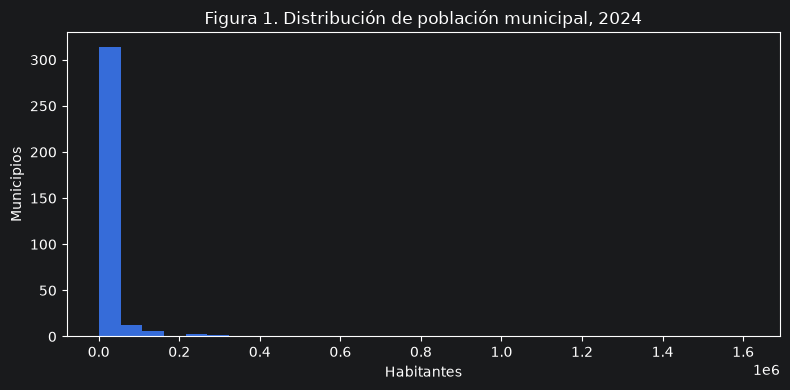

In [83]:
plt.figure(figsize=(8, 4));
plt.hist(df.poblacion_2024, bins=30);
plt.title("Figura 1. Distribución de población municipal, 2024");
plt.xlabel("Habitantes");
plt.ylabel("Municipios");
plt.tight_layout();
carpeta_exportaciones = Path("exportaciones")
carpeta_exportaciones.mkdir(parents=True, exist_ok=True)
ruta_imagen = carpeta_exportaciones / "grafico_01_distribucion_poblacion.png"
plt.savefig(ruta_imagen, dpi=200, bbox_inches="tight")
print(f"Imagen guardada en: {ruta_imagen.resolve()}")
plt.show()

Imagen guardada en: /home/usic03/PycharmProjects/ProyectoFinalDeSemestre/exportaciones/grafico_02_edad_mediana.png


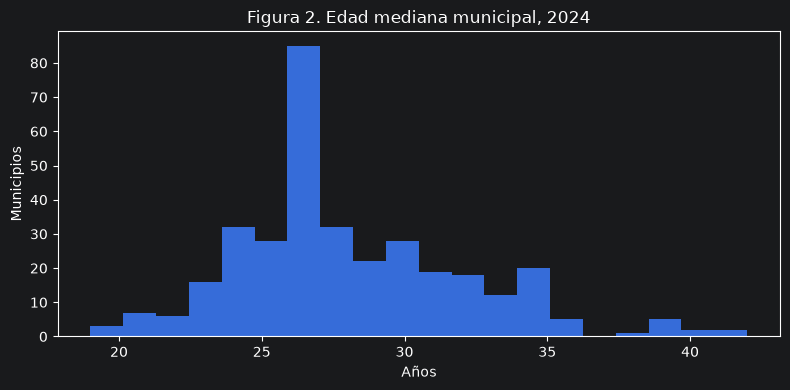

In [84]:
plt.figure(figsize=(8, 4));
plt.hist(df.edad_mediana_2024, bins=20);
plt.title("Figura 2. Edad mediana municipal, 2024");
plt.xlabel("Años");
plt.ylabel("Municipios");
plt.tight_layout();
carpeta_exportaciones = Path("exportaciones")
carpeta_exportaciones.mkdir(parents=True, exist_ok=True)
ruta_imagen = carpeta_exportaciones / "grafico_02_edad_mediana.png"
plt.savefig(ruta_imagen, dpi=200, bbox_inches="tight")
print(f"Imagen guardada en: {ruta_imagen.resolve()}")
plt.show()

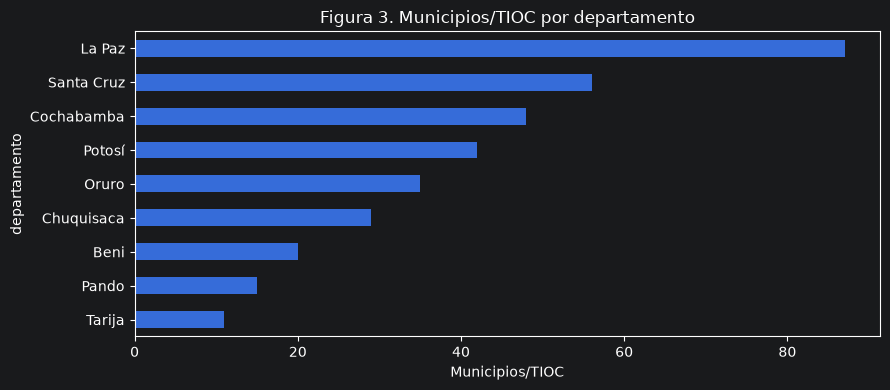

In [85]:
plt.figure(figsize=(9, 4));
df.departamento.value_counts().sort_values().plot.barh();
plt.title("Figura 3. Municipios/TIOC por departamento");
plt.xlabel("Municipios/TIOC");
plt.tight_layout();
plt.show()

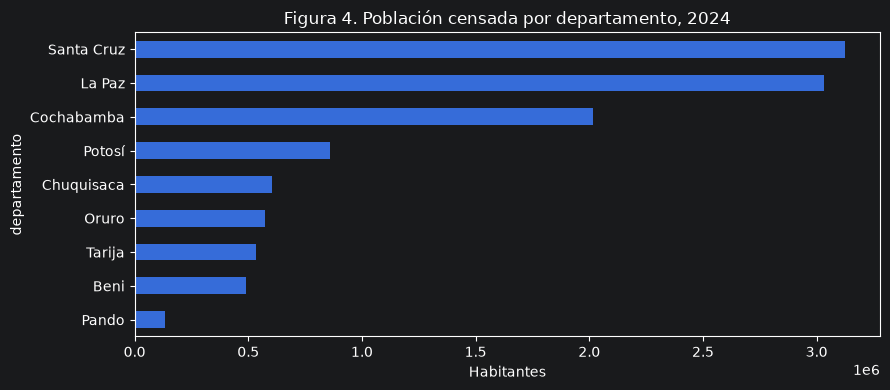

In [86]:
plt.figure(figsize=(9, 4));
df.groupby("departamento").poblacion_2024.sum().sort_values().plot.barh();
plt.title("Figura 4. Población censada por departamento, 2024");
plt.xlabel("Habitantes");
plt.tight_layout();
plt.show()

Imagen guardada en: /home/usic03/PycharmProjects/ProyectoFinalDeSemestre/exportaciones/grafico_05_tasa_crecimiento.png


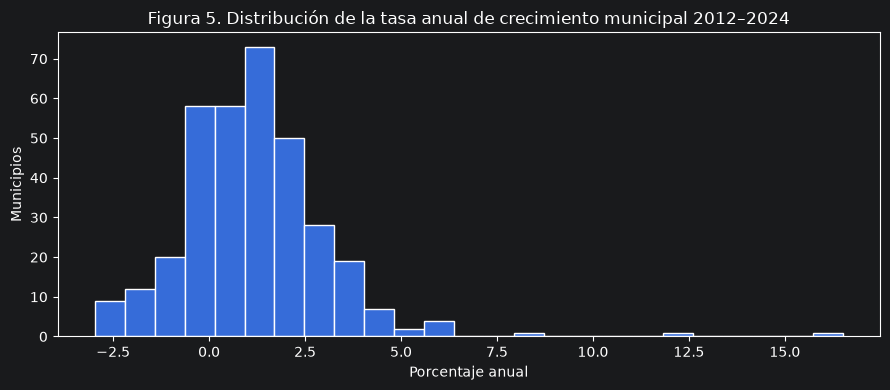

In [87]:
plt.figure(figsize=(9, 4))
plt.hist(df.tasa_anual_pct_2012_2024.dropna(), bins=25, edgecolor="white")
plt.title("Figura 5. Distribución de la tasa anual de crecimiento municipal 2012–2024")
plt.xlabel("Porcentaje anual")
plt.ylabel("Municipios")
plt.tight_layout()
carpeta_exportaciones = Path("exportaciones")
carpeta_exportaciones.mkdir(parents=True, exist_ok=True)
ruta_imagen = carpeta_exportaciones / "grafico_05_tasa_crecimiento.png"
plt.savefig(ruta_imagen, dpi=200, bbox_inches="tight")
print(f"Imagen guardada en: {ruta_imagen.resolve()}")
plt.show()

In [88]:
print("Municipios con crecimiento absoluto negativo:", (df.crecimiento_absoluto_2012_2024 < 0).sum())
print("Municipios con mayoría femenina:", (df.porcentaje_mujeres_2024 > 50).sum())
print("Población municipal por departamento:\n", df.groupby("departamento").poblacion_2024.sum().sort_values(ascending=False))
print("Correlación exploratoria (edad mediana vs tasa de crecimiento):", df[["edad_mediana_2024", "tasa_anual_pct_2012_2024"]].corr().iloc[0, 1])

Municipios con crecimiento absoluto negativo: 83
Municipios con mayoría femenina: 77
Población municipal por departamento:
 departamento
Santa Cruz    3122605
La Paz        3030917
Cochabamba    2016357
Potosí         861292
Chuquisaca     606027
Oruro          571471
Tarija         534210
Beni           488260
Pando          134194
Name: poblacion_2024, dtype: int64
Correlación exploratoria (edad mediana vs tasa de crecimiento): -0.11198901811963935
